# E7 results

Set `RESULT_PATH` to an E7 result JSON and run all cells. When you open a
retrieval result, the notebook also loads `encoding.json` from the same run
directory if present. Older retrieval files can be opened without CUDA
memory measurements.

In [8]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator, NullLocator

RESULT_PATH = Path("results/E7/e7_smoke_qscht8pb/retrieval_encoded.json").expanduser()

if not RESULT_PATH.is_absolute() and Path.cwd().name == "notebooks":
    RESULT_PATH = Path("..") / RESULT_PATH


with RESULT_PATH.open(encoding="utf-8") as file:
    measurements = json.load(file)["measurements"]

retrieval_measurements = measurements if isinstance(measurements, list) else None
encoding_measurements = measurements if isinstance(measurements, dict) else None
print(RESULT_PATH)

encoding_path = RESULT_PATH.with_name("encoding.json")
if retrieval_measurements is not None and encoding_path.is_file():
    with encoding_path.open(encoding="utf-8") as file:
        encoding_measurements = json.load(file)["measurements"]
    print(encoding_path)

def show_table(title, data, columns):
    """Display one metric group with short column names."""
    display(Markdown(f"**{title}**"))
    display(data[list(columns)].rename(columns=columns).round(3))

../results/E7/e7_smoke_qscht8pb/retrieval_encoded.json
../results/E7/e7_smoke_qscht8pb/encoding.json


## Retrieval

Mean and p95 are per batch. Amortized ms/query is mean batch time divided by
batch size. Corpus bytes count the stored representation. Allocator peak
and additional peak bytes describe VRAM during a separate warmed search batch.

24 documents · 8 queries · batch size 4


**Search latency and throughput**

,Method,Width,Mean ms/batch,p95 ms/batch,Amortized ms/query,Queries/s
0,Qwen3 (full),Full,0.238,0.260,0.059,16809.171
1,MRL,2,0.205,0.212,0.051,19502.522
2,CSRv2,2,0.257,0.275,0.064,15578.187


**Corpus storage**

,Method,Width,Bytes/doc,Corpus KiB
0,Qwen3 (full),Full,10240.000,240.000
1,MRL,2,8.000,0.188
2,CSRv2,2,32.667,0.766


**Search VRAM**

,Method,Width,Peak MiB,Additional peak KiB
0,Qwen3 (full),Full,108.609,5.5
1,MRL,2,108.260,5.5
2,CSRv2,2,108.729,5.5


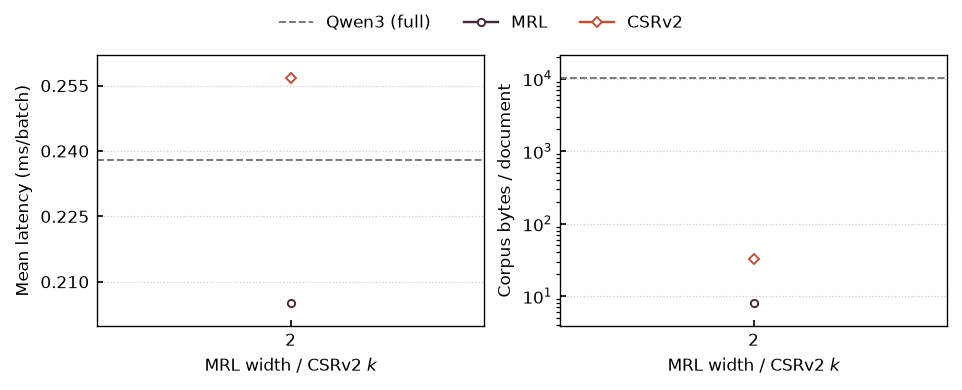

In [9]:
if retrieval_measurements is not None:
    retrieval = pd.json_normalize(retrieval_measurements)
    retrieval["amortized_ms_per_query"] = (
        retrieval["ms_per_batch_mean"] / retrieval["query_batch_size"]
    )
    retrieval["corpus_bytes_per_doc"] = retrieval["corpus_bytes"] / retrieval["documents"]


    styles = {
        "qwen_dense": ("Qwen3 (full)", "#737373", None),
        "mrl": ("MRL", "#46263b", "o"),
        "csrv2": ("CSRv2", "#c64b32", "D"),
    }
    widths = sorted(retrieval["k"].dropna().unique())
    retrieval["method_name"] = retrieval["method"].map(lambda method: styles.get(method, (method,))[0])
    retrieval["width_label"] = retrieval["k"].astype("Int64").astype("string").fillna("Full")
    methods = {"method_name": "Method", "width_label": "Width"}
    sizes = retrieval[["documents", "queries", "query_batch_size"]].drop_duplicates()
    if len(sizes) == 1:
        documents, queries, batch_size = sizes.iloc[0]
        print(f"{documents:,} documents · {queries:,} queries · batch size {batch_size}")
    show_table("Search latency and throughput", retrieval, {
        **methods, "ms_per_batch_mean": "Mean ms/batch", "ms_per_batch_p95": "p95 ms/batch",
        "amortized_ms_per_query": "Amortized ms/query", "queries_per_second": "Queries/s",
    })
    retrieval["corpus_kib"] = retrieval["corpus_bytes"] / 2**10
    show_table("Corpus storage", retrieval, {
        **methods, "corpus_bytes_per_doc": "Bytes/doc", "corpus_kib": "Corpus KiB",
    })
    memory_fields = {"cuda_memory.peak_allocated_bytes", "cuda_memory.extra_peak_bytes"}
    if memory_fields.issubset(retrieval.columns):
        memory = retrieval.dropna(subset=sorted(memory_fields)).copy()
        if not memory.empty:
            memory["peak_mib"] = memory["cuda_memory.peak_allocated_bytes"] / 2**20
            memory["extra_kib"] = memory["cuda_memory.extra_peak_bytes"] / 2**10
            show_table("Search VRAM", memory, {
                **methods, "peak_mib": "Peak MiB", "extra_kib": "Additional peak KiB",
            })

    figure, axes = plt.subplots(1, 2, figsize=(6.3, 2.5), dpi=150, layout="constrained")
    for axis, metric, label in zip(
        axes,
        ("ms_per_batch_mean", "corpus_bytes_per_doc"),
        ("Mean latency (ms/batch)", "Corpus bytes / document"),
    ):
        for method, rows in retrieval.groupby("method", sort=False):
            name, color, marker = styles.get(method, (method, None, "o"))
            sized = rows.dropna(subset=["k"]).sort_values("k")
            if sized.empty:
                axis.axhline(rows[metric].iloc[0], ls="--", lw=0.9, color=color, label=name)
            else:
                axis.plot(
                    sized["k"], sized[metric], color=color, label=name, lw=1.15,
                    marker=marker, ms=3.5, mfc="white", mew=0.9,
                )
        if widths:
            axis.set_xscale("log", base=2)
            axis.set_xticks(widths, labels=[str(int(width)) for width in widths])
        else:
            axis.set_xticks([])
        axis.xaxis.set_minor_locator(NullLocator())
        axis.set_xlabel("MRL width / CSRv2 $k$", fontsize=8)
        axis.set_ylabel(label, fontsize=8)
        axis.margins(y=0.10)
        axis.tick_params(axis="both", labelsize=8, direction="in", length=3)
        axis.set_axisbelow(True)
        axis.grid(axis="y", color="0.8", linestyle=":", linewidth=0.6)
        for spine in axis.spines.values():
            spine.set_linewidth(0.65)

    axes[0].yaxis.set_major_locator(MaxNLocator(nbins=5))
    axes[0].ticklabel_format(axis="y", style="plain", useOffset=False)
    axes[1].set_yscale("log")
    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(handles, labels, loc="outside upper center", ncol=len(labels), frameon=False, fontsize=8)
    plt.show()

## Encoding

Wall time covers the encoding pass. The phase chart shows mean milliseconds
per profiled batch on the CUDA stream. The two panels use independent y-axes.
The backbone interval can include waits while the CPU prepares text.

**Encoding totals**

,Model,Input,Texts,Seconds,Texts/s
0,Qwen3,query,8,0.223,35.883
1,Qwen3,document,24,4.557,5.267
2,CSRv2,query,8,0.271,29.546
3,CSRv2,document,24,4.922,4.876


**Encoding breakdown**

,Model,Input,Profiled batches,Backbone ms/batch,SAE + top-k ms/batch
0,Qwen3,query,2,111.431,NaN
1,Qwen3,document,6,759.483,NaN
2,CSRv2,query,2,135.142,0.203
3,CSRv2,document,6,820.160,0.208


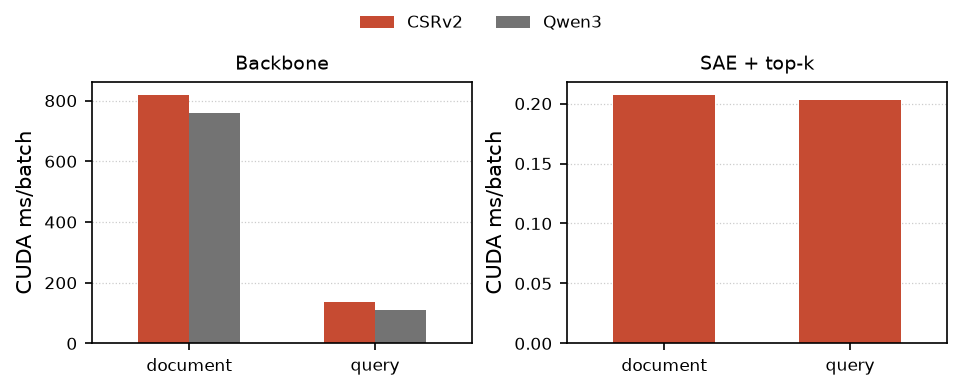

In [10]:
if encoding_measurements is not None:
    encoding = pd.DataFrame([
        {"model": model, "role": role, **stats}
        for model, roles in encoding_measurements.items()
        for role, stats in roles.items()
    ])
    names = {"dense": "Qwen3", "csrv2": "CSRv2"}
    colors = {"Qwen3": "#737373", "CSRv2": "#c64b32"}
    encoding["model"] = encoding["model"].replace(names)
    identity = {"model": "Model", "role": "Input"}
    show_table("Encoding totals", encoding, {
        **identity, "texts": "Texts", "seconds": "Seconds", "texts_per_second": "Texts/s",
    })

    phases = {
        "backbone_stream_ms_per_batch_mean": "Backbone",
        "sae_stream_ms_per_batch_mean": "SAE + top-k",
    }
    phases = {key: label for key, label in phases.items()
              if key in encoding and encoding[key].notna().any()}
    if phases:
        show_table("Encoding breakdown", encoding, {
            **identity, "profiled_batches": "Profiled batches",
            **{key: f"{label} ms/batch" for key, label in phases.items()},
        })
        figure, axes = plt.subplots(
            1, len(phases), figsize=(6.3, 2.5), dpi=150, layout="constrained", squeeze=False,
        )
        for axis, (key, label) in zip(axes[0], phases.items()):
            values = encoding.dropna(subset=[key]).pivot(index="role", columns="model", values=key)
            values.plot.bar(
                ax=axis, color=[colors.get(model, "#537b96") for model in values.columns],
                rot=0, ylabel="CUDA ms/batch", xlabel="", width=0.55, legend=False,
            )
            axis.set_title(label, fontsize=9)
            axis.tick_params(labelsize=8)
            axis.set_axisbelow(True)
            axis.grid(axis="y", color="0.8", linestyle=":", linewidth=0.6)
        handles = {}
        for axis in axes[0]:
            artists, labels = axis.get_legend_handles_labels()
            handles.update(zip(labels, artists))
        figure.legend(
            handles.values(), handles.keys(), loc="outside upper center",
            ncol=len(handles), frameon=False, fontsize=8,
        )
        plt.show()
else:
    print("No encoding results are available for this retrieval run.")